<a href="https://colab.research.google.com/github/emilytiari/Python/blob/main/Fundamentos_IA_industria_predi%C3%A7%C3%B5es.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
# Importação da bibliotecas

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Separa a base de dadosbem treino e teste
from sklearn.model_selection import train_test_split

# Padroniza a  base de dados para uso em algoritmos de regressão em redes neurais
from sklearn.preprocessing import StandardScaler

# Gera as métricas para avaliação dos modelos treinados
from sklearn.metrics import accuracy_score, mean_absolute_error, confusion_matrix, ConfusionMatrixDisplay

# Biblioteca de regressão linear e logistica
from sklearn.linear_model import LogisticRegression, LinearRegression

#Biblioteca de árvore de decisão
from sklearn.tree import DecisionTreeClassifier

#Biblioteca KMeans (clusterização)
from sklearn.cluster import KMeans

# Biblioteca redes neurais
from sklearn.neural_network import MLPClassifier


# Configurações visuais simples
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

from sklearn.metrics import classification_report, balanced_accuracy_score, recall_score

In [6]:
# Carregamento da base
df= pd.read_csv("/content/base_industrial_desbalanceada - base_industrial_desbalanceada.csv")

#visualização da base de dados
df.head()

,rpm,temperatura_motor_c,vibracao_mm_s,corrente_a,pressao_bar,horas_operacao,carga_pct,umidade_pct,indice_desgaste,falha,regime_operacao
0,1679,5.271.209.750.114.330,2.484.242.924.409.700,14.048.098.482.287.500,5.984.625.590.036.410,4476,55.943.292.779.866,7.745.193.308.396.360,28.377.503.654.735,0,leve
1,1075,7.333.913.746.616.030,34.837.998.712.969.200,20.448.905.058.297.600,5.766.884.225.029.770,1055,8.406.767.365.500.100,4.947.306.239.850.050,33.067.093.140.150.600,0,critico
2,1828,7.774.924.523.791.540,38.683.078.722.103.100,21.500.123.976.671.300,7.721.785.408.188.000,839,9.350.608.259.410.680,5.901.087.572.944.100,3.453.692.295.878.530,1,critico
3,1492,7.083.099.693.142.640,3.001.367.456.694.210,16.660.105.598.502.100,5.496.610.008.794.720,3933,7.037.115.329.181.160,5.495.678.345.366.100,3.496.127.346.848.450,0,normal
4,1000,6.639.969.371.822.470,37.188.313.878.281.500,17.947.670.342.376.500,5.228.560.999.836.880,2238,8.382.786.243.169.750,545.923.495.112.862,35.764.671.611.716.600,0,critico


In [7]:
# Conferencia rápida da qualidade da base
print("Quantidade de linhas e colunas", df.shape)
print("\nValores ausentes por coluna")
print(df.isna().sum())
print("\nDuplicadas: ", df.duplicated().sum())

# Resumo estatístico das variaveis
df.describe()

Quantidade de linhas e colunas (300, 11)

Valores ausentes por coluna
rpm                    0
temperatura_motor_c    0
vibracao_mm_s          0
corrente_a             0
pressao_bar            0
horas_operacao         0
carga_pct              0
umidade_pct            0
indice_desgaste        0
falha                  0
regime_operacao        0
dtype: int64

Duplicadas:  0


,rpm,horas_operacao,falha
count,300.000000,300.000000,300.000000
mean,1513.030000,2422.040000,0.300000
std,193.662334,1394.401932,0.459023
min,1000.000000,103.000000,0.000000
25%,1383.000000,1217.500000,0.000000
50%,1516.000000,2382.500000,0.000000
75%,1636.250000,3563.750000,1.000000
max,2000.000000,4969.000000,1.000000


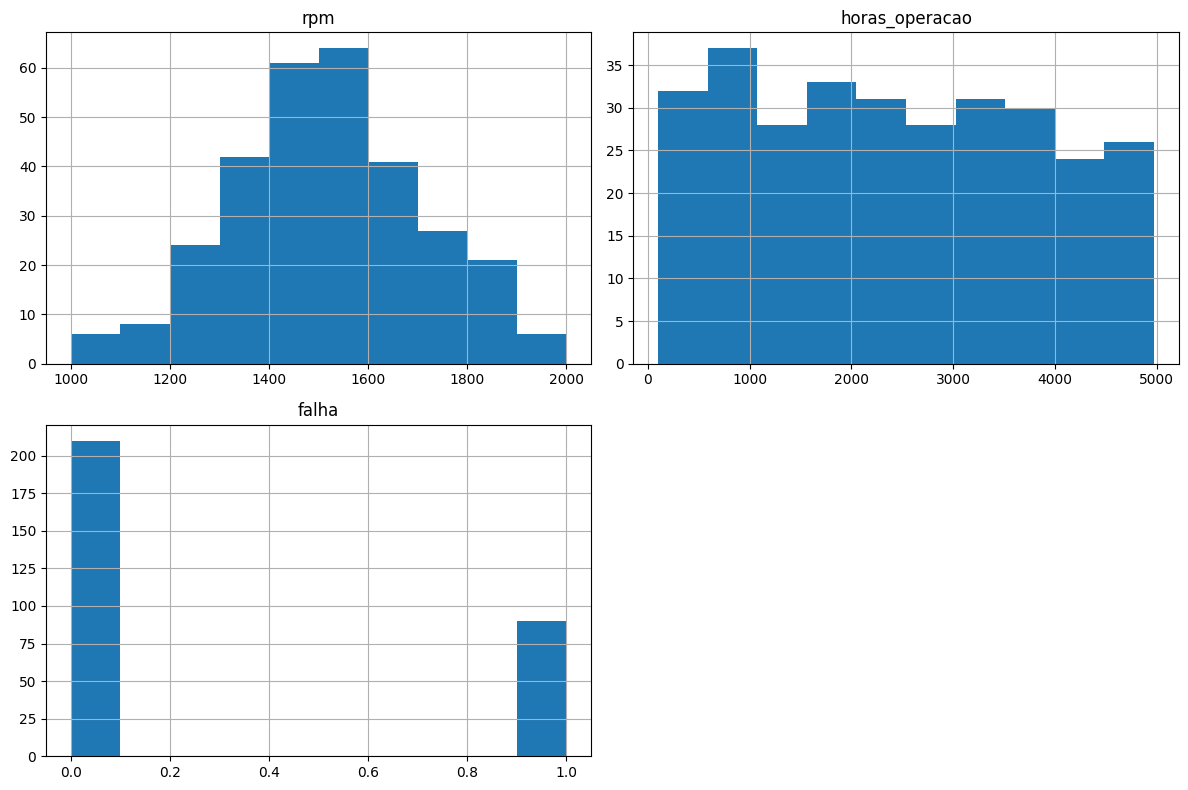

In [8]:
# Histograma simples
df.hist(figsize=(12,8))
plt.tight_layout()
plt.show()

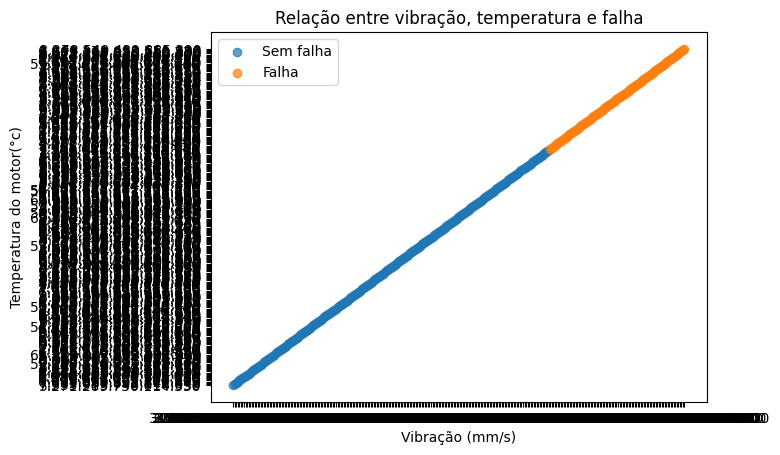

In [16]:
# Relação entre vibração e temperatura

cores = df['falha'].map({
    0: "Sem falha",
    1: "Falha"
})
for categoria in ["Sem falha", "Falha"]:
  subset = df[cores==categoria]
  plt.scatter(subset["vibracao_mm_s"],
              subset["temperatura_motor_c"],
              label=categoria,
              alpha=0.7)
plt.xlabel("Vibração (mm/s)")
plt.ylabel("Temperatura do motor(°c)")
plt.title("Relação entre vibração, temperatura e falha")
plt.legend()
plt.show()

In [17]:
# Limites assumidos para interpretar os números deste CSV.
limites = {
    "temperatura_motor_c": 95, "vibracao_mm_s": 6,
    "corrente_a": 35, "pressao_bar": 8.5,
    "carga_pct": 100, "umidade_pct": 80, "indice_desgaste": 100
}

for coluna, limite in limites.items():
    texto = df[coluna].astype(str)
    varios_pontos = texto.str.count(r"\.") > 1
    # Retira os pontos somente dos textos com formato alterado.
    texto.loc[varios_pontos] = texto.loc[varios_pontos].str.replace(
        ".", "", regex=False)
    df[coluna] = pd.to_numeric(texto).astype(float)
    # Divide por 10 até encaixar o número na escala assumida.
    while (varios_pontos & (df[coluna] > limite)).any():
        ajustar = varios_pontos & (df[coluna] > limite)
        df.loc[ajustar, coluna] = df.loc[ajustar, coluna] / 10

# Converte o alvo diretamente, preservando 0 e 1.
df["falha"] = pd.to_numeric(df["falha"])
print(df.dtypes)
print(df.head())


rpm                      int64
temperatura_motor_c    float64
vibracao_mm_s          float64
corrente_a             float64
pressao_bar            float64
horas_operacao           int64
carga_pct              float64
umidade_pct            float64
indice_desgaste        float64
falha                    int64
regime_operacao         object
dtype: object
    rpm  temperatura_motor_c  vibracao_mm_s  corrente_a  pressao_bar  horas_operacao  carga_pct  umidade_pct  \
0  1679            52.712098       2.484243   14.048098     5.984626            4476  55.943293    77.451933   
1  1075            73.339137       3.483800   20.448905     5.766884            1055  84.067674    49.473062   
2  1828            77.749245       3.868308   21.500124     7.721785             839  93.506083    59.010876   
3  1492            70.830997       3.001367   16.660106     5.496610            3933  70.371153    54.956783   
4  1000            66.399694       3.718831   17.947670     5.228561            2238 

In [18]:
# Limites assumidos para interpretar os números deste CSV.
limites = {
    "temperatura_motor_c": 95, "vibracao_mm_s": 6,
    "corrente_a": 35, "pressao_bar": 8.5,
    "carga_pct": 100, "umidade_pct": 80, "indice_desgaste": 100
}

for coluna, limite in limites.items():
    texto = df[coluna].astype(str)
    varios_pontos = texto.str.count(r"\.") > 1
    # Retira os pontos somente dos textos com formato alterado.
    texto.loc[varios_pontos] = texto.loc[varios_pontos].str.replace(
        ".", "", regex=False)
    df[coluna] = pd.to_numeric(texto).astype(float)
    # Divide por 10 até encaixar o número na escala assumida.
    while (varios_pontos & (df[coluna] > limite)).any():
        ajustar = varios_pontos & (df[coluna] > limite)
        df.loc[ajustar, coluna] = df.loc[ajustar, coluna] / 10

# Converte o alvo diretamente, preservando 0 e 1.
df["falha"] = pd.to_numeric(df["falha"])
print(df.dtypes)
print(df.head())

rpm                      int64
temperatura_motor_c    float64
vibracao_mm_s          float64
corrente_a             float64
pressao_bar            float64
horas_operacao           int64
carga_pct              float64
umidade_pct            float64
indice_desgaste        float64
falha                    int64
regime_operacao         object
dtype: object
    rpm  temperatura_motor_c  vibracao_mm_s  corrente_a  pressao_bar  horas_operacao  carga_pct  umidade_pct  \
0  1679            52.712098       2.484243   14.048098     5.984626            4476  55.943293    77.451933   
1  1075            73.339137       3.483800   20.448905     5.766884            1055  84.067674    49.473062   
2  1828            77.749245       3.868308   21.500124     7.721785             839  93.506083    59.010876   
3  1492            70.830997       3.001367   16.660106     5.496610            3933  70.371153    54.956783   
4  1000            66.399694       3.718831   17.947670     5.228561            2238 

Separar treino e teste

In [27]:
features = [
    "rpm",
    "temperatura_motor_c",
    "vibracao_mm_s",
    "corrente_a",
    "pressao_bar",
    "horas_operacao",
    "carga_pct",
    "umidade_pct"
]

# X contem as entradas do DataFrame

X = df[features]

# Y contém a resposta que o modelo aprenderá a prever

y = df["falha"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Treino: ", X_train.shape)
print("Teste: ", X_test.shape)

Treino:  (225, 8)
Teste:  (75, 8)


In [28]:
# Colunas com as medições que o modelo usará para prever uma falha.
features = [
    "rpm",
    "temperatura_motor_c",
    "vibracao_mm_s",
    "corrente_a",
    "pressao_bar",
    "horas_operacao",
    "carga_pct",
    "umidade_pct"
]

# X contém as medições; y contém a resposta correta (0 ou 1).
X = df[features]
y = df["falha"]

# Separa 75% dos dados para treino e 25% para teste.
# stratify=y mantém aproximadamente a mesma proporção de falhas nos dois grupos.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Aprende a escala das medições usando somente os dados de treino.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Aplica aos dados de teste a mesma escala aprendida no treino.
X_test_scaled = scaler.transform(X_test)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)

Treino: (225, 8)
Teste: (75, 8)


Regressão lógica - Preve a falha

In [30]:
modelo_log = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

# Treina o modelo com as medições e as resposta corretas
modelo_log.fit(X_train_scaled, y_train)

# Pede ao modelo que preveja as respostas dos dados de teste
pred_log = modelo_log.predict(X_test_scaled)

# Mostra a proporção de previsões corretas no testes
print("Acurácia: ", round(accuracy_score(y_test, pred_log), 3))

# Mostra a proporção de falhar que o modelo conseguiu identificar
print("Recall de falhar: ", round(recall_score(y_test, pred_log), 3))

print("Acurácia sempre sem falhas:", round((y_test==0).mean(),3))


Acurácia:  0.947
Recall de falhar:  1.0
Acurácia sempre sem falhas: 0.707


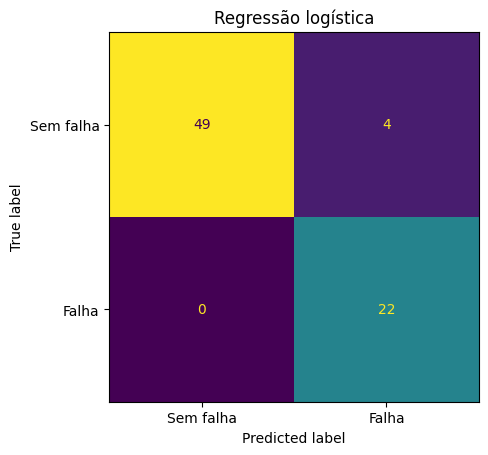

In [31]:
matriz = confusion_matrix(y_test, pred_log, labels=[0,1])

# Mostra a matrizcomo um gráfico com nomes no lugar de 0 e 1

ConfusionMatrixDisplay(
    matriz,
    display_labels=['Sem falha',"Falha"]
).plot(colorbar=False)

plt.title("Regressão logística")
plt.show()

# Árvore de Decisão = preve falha

In [33]:
modelo_arvore = DecisionTreeClassifier(
    max_depth=4,
    class_weight="balanced",
    random_state=42
)
# Treina a arvore com as medições e as respostas corretas
modelo_arvore.fit(X_train, y_train)

# Faz a previsão usando as medições separadas
pred_arvore = modelo_arvore.predict(X_test)

print("Acurácia: ", round(accuracy_score(y_test,pred_arvore),3))

print("Recall de falhas: ", round(recall_score(y_test, pred_arvore),3))



Acrácia:  0.827
Recall de falhas:  0.864


In [36]:
# Preve o indice de desgastes
y_reg = df["indice_desgaste"]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y_reg, test_size=0.25, random_state=42
)

# Cria e treina o modelo com medições e desgastes conhecidos
modelo_reg = LinearRegression()
modelo_reg.fit(X_train_r, y_train_r)

# Preve o desgaste da maquina
pred_reg = modelo_reg.predict(X_test_r)

# Calcula o tamanho médio dos erros
print("Erro médio absoluto (MAE)",
      round(mean_absolute_error(y_test_r, pred_reg),3))

# Mostra os valores reais ao lado do previsto
pd.DataFrame({
    "real": y_test_r.values,
    "Previsto": pred_reg
})

Erro médio absoluto (MAE) 1.655


,real,Previsto
0,34.356223,32.293253
1,31.932551,36.383599
2,35.450841,39.284149
3,32.454341,31.586917
4,28.881108,29.843967
...,...,...
70,35.543557,35.885538
71,33.672665,30.588711
72,39.503517,36.530744
73,37.881948,33.187487


#Agrupamento

In [45]:
colunas_cluster = ["vibracao_mm_s",
                   "temperatura_motor_c",
                   "carga_pct"]

# Colocar as 3 medições em escalas comparaveis
scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(df[colunas_cluster])

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['grupo'] = kmeans.fit_predict(X_cluster_scaled)

#Mostra a média das medições das maquinas em cada grupo
print(df.groupby("grupo")[colunas_cluster].mean().round(2))



       vibracao_mm_s  temperatura_motor_c  carga_pct
grupo                                               
0               3.29                79.58      76.49
1               4.07                68.30      56.07
2               3.00                65.22      76.45


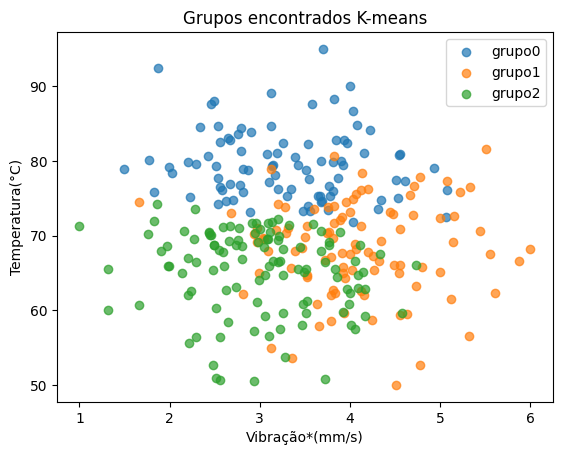

In [51]:
for grupo in [0,1,2]:
  dados_grupo=df[df['grupo']==grupo]
  plt.scatter(
      dados_grupo['vibracao_mm_s'],
      dados_grupo["temperatura_motor_c"],
      label=f"grupo{grupo}",alpha=0.7
  )

plt.xlabel("Vibração*(mm/s)")
plt.ylabel("Temperatura(°C)")
plt.title("Grupos encontrados K-means")
plt.legend()
plt.show()

In [56]:
# Cria uma rede neural simples com uma camara de 10 neuronios
modelo_mlp = MLPClassifier(
    hidden_layer_sizes=(10,),
    solver="lbfgs",
    alpha=0.1,
    max_iter=2000,
    random_state=42
)

# Treina a rede com as medições padronizadas e as respostas corretas
modelo_mlp.fit(X_train_scaled, y_train)

#Preve se as maquinas dos testes tem falha (1) ou não (0)
pred_mlp = modelo_mlp.predict(X_test_scaled)


# Mostrar os resultados
print("Acurácia: ", round(accuracy_score(y_test, pred_mlp),3))

# Mostra a proporção de falhas
print("Recall: ", round(recall_score(y_test, pred_mlp),3))

Acurácia:  0.973
Recall:  0.955


In [61]:
# Cria uma tabela comparando os 3 modelos
comparacao = pd.DataFrame({
    "Modelo": [
        "Regressão Logística",
        "Árvore de Decisão",
        "Rede Neural"
         ],
    #Acurária: Prioporção de acertos entre todos os casos
    "Acurácia": [
        accuracy_score(y_test, pred_log),
        accuracy_score(y_test, pred_arvore),
        accuracy_score(y_test, pred_mlp)
        # Falta incluir o terceiro modelo aqui para evitar erro de tamanho!
    ],

    #Recall: Proporção de falhas reais que cada modelo identificou
    "Recall de Falhas":[
    recall_score(y_test, pred_log),
    recall_score(y_test, pred_arvore),
    recall_score(y_test, pred_mlp)
 ]
})
print(comparacao.round(3))

                Modelo  Acurácia  Recall de Falhas
0  Regressão Logística     0.947             1.000
1    Árvore de Decisão     0.827             0.864
2          Rede Neural     0.973             0.955


#Testando a maquina

In [63]:
nova_maquina = pd.DataFrame([{
    "rpm": 1600,
    "temperatura_motor_c": 75,
    "vibracao_mm_s": 3,
    "corrente_a" :18,
    "pressao_bar": 60,
    "horas_operacao":2500,
    "carga_pct":70,
    "umidade_pct":55

}])

nova_maquina = nova_maquina[features]
nova_maquina

,rpm,temperatura_motor_c,vibracao_mm_s,corrente_a,pressao_bar,horas_operacao,carga_pct,umidade_pct
0,1600,75,3,18,60,2500,70,55


In [67]:
# Usa a padronização já aprendida; não chama fit novamente.
nova_scaled = scaler.transform(nova_maquina)

falha_prevista = modelo_log.predict(nova_scaled)[0]
probabilidade = modelo_log.predict_proba(nova_scaled)[0][1]
desgaste_previsto = modelo_reg.predict(nova_maquina)[0]

print("Classe prevista:", "Falha" if falha_prevista == 1 else "Sem falha")
print(f"Estimativa do modelo para falha: {probabilidade:.1%}")
print("Desgaste estimado:", round(desgaste_previsto, 2))
print("Estimativas didáticas; não são diagnóstico nem garantia de falha futura.")


Classe prevista: Sem falha
Estimativa do modelo para falha: 0.0%
Desgaste estimado: 13.81
Estimativas didáticas; não são diagnóstico nem garantia de falha futura.
